# ERA5: two separate experiments in PyTorch

**Experiment 1:** Can a nonlinear autoencoder reconstruct daily weather maps better than EOF/PCA at the same compression size?

**Experiment 2:** Can a temporal Transformer predict next-day weather maps from seven previous daily maps compressed by AE or EOF/PCA?

This notebook uses ERA5 2018–2024 and five variables: `t2m`, `d2m`, `msl`, `u10`, `v10`. Sub-daily instantaneous records are averaged into daily maps. It does not use precipitation.

Run all cells in order with your `data/ERA5/*_instant.nc` files available. Outputs have deliberately been cleared: the revised preprocessing requires fresh training. Three seeds increase training time approximately threefold. Required packages: numpy, torch, h5py, matplotlib; cartopy for the optional geographic figures.

## Comparison of the two tasks

| Aspect | Experiment 1: reconstruction | Experiment 2: forecasting |
|---|---|---|
| Question | How well can a map be compressed and rebuilt? | Can we predict tomorrow from the previous seven days? |
| Input | One daily, five-variable map | Seven consecutive daily latent vectors |
| Target | The same day's map | The following day's map |
| Models | Dense deterministic AE | Encoder-only temporal Transformers on AE/PCA codes |
| Baselines | EOF/PCA at equal latent size | Climatology, anomaly persistence, physical-map persistence |
| Latent dimensions | 2, 4, 8, 16, 32, 64 | Fixed at 16 before test evaluation |
| Main metrics | Per-variable physical-unit RMSE; normalized RMSE | Per-variable physical-unit RMSE; normalized RMSE |
| Supporting metric | Held-out reconstruction variance explained | Skill relative to each forecasting baseline |
| Access to target map | Yes, as the encoder input | No |
| Data split | 2018–2022 train; 2023 validation; 2024 test | Same split; windows stay within a split |

**Do not compare reconstruction RMSE with forecasting RMSE as a model ranking. They measure different tasks.** The AE is not a VAE: there is no stochastic latent distribution or KL penalty. A convolutional AE is an optional future extension.

## Shared setup and data

In [9]:
from __future__ import annotations

import gc
 
import matplotlib.pyplot as plt
import numpy as np
import torch
from pathlib import Path
from torch import nn

SEED = 42
SEEDS = (42, 43, 44)
CLIMATOLOGY_HALF_WINDOW = 15  # circular +/-15 calendar days
torch.manual_seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "homework3" / "data" ).is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/ERA5 while searching the current directory and its parents. "
        "Open this notebook from the project checkout."
    )

DATA_DIR = PROJECT_ROOT  / "homework3"  /  "data" 
OUTPUT_DIR = PROJECT_ROOT / "model"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VARIABLES = ("t2m", "d2m", "msl", "u10", "v10")
UNITS = {"t2m": "K", "d2m": "K", "msl": "Pa", "u10": "m s$^{-1}$", "v10": "m s$^{-1}$"}
LATENT_SIZES = (2, 4, 8, 16, 32, 64)
TRAIN_YEARS = set(range(2018, 2023))
SPLIT_YEARS = {"train": TRAIN_YEARS, "validation": {2023}, "test": {2024}}

if hasattr(torch, "xpu") and torch.xpu.is_available():
    DEVICE = torch.device("xpu")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"Project root: {PROJECT_ROOT}")
print(f"Device: {DEVICE}")
print(f"Input directory: {DATA_DIR}")

Project root: s:\git-repo\pgr\py-torch\courses\STAT41140-AI for Weather and Climate
Device: cuda
Input directory: s:\git-repo\pgr\py-torch\courses\STAT41140-AI for Weather and Climate\homework3\data


### Daily maps and chronological split
The loader expects HDF5-compatible NetCDF files, Unix-second `valid_time`, and unpacked finite variable values in the listed units. Check the printed dates and grid against your download. This is not a general loader for packed/CF-encoded NetCDF files.

In [12]:
import h5py
instant_files = sorted(DATA_DIR.rglob("*_instant.nc"))
if not instant_files:
    raise FileNotFoundError(f"No *_instant.nc files found under {DATA_DIR}.")

daily_dates_by_file = []
daily_maps_by_file = []
latitude = None
longitude = None

for filename in instant_files:
    with h5py.File(filename, "r") as dataset:
        required = ("valid_time", "latitude", "longitude", *VARIABLES)
        missing = [name for name in required if name not in dataset]
        if missing:
            raise KeyError(f"{filename} is missing required datasets: {missing}")

        times = np.asarray(dataset["valid_time"][:], dtype=np.int64).reshape(-1)
        if times.size == 0:
            raise ValueError(f"{filename} contains no valid_time records.")
        current_latitude = np.asarray(dataset["latitude"][:], dtype=np.float64)
        current_longitude = np.asarray(dataset["longitude"][:], dtype=np.float64)
        if latitude is None:
            latitude, longitude = current_latitude, current_longitude
        elif not (
            np.array_equal(latitude, current_latitude)
            and np.array_equal(longitude, current_longitude)
        ):
            raise ValueError(f"Grid coordinates differ in {filename}.")

        day_ids, inverse = np.unique(times // 86400, return_inverse=True)
        counts = np.bincount(inverse).astype(np.float32)
        daily_maps = np.empty(
            (len(day_ids), len(VARIABLES), len(latitude), len(longitude)),
            dtype=np.float32,
        )
        for variable_index, variable in enumerate(VARIABLES):
            frames = np.asarray(dataset[variable][:], dtype=np.float32)
            if frames.shape != (len(times), len(latitude), len(longitude)):
                raise ValueError(
                    f"Unexpected shape for {variable} in {filename}: {frames.shape}."
                )
            daily_variable = np.zeros(
                (len(day_ids), len(latitude), len(longitude)), dtype=np.float32
            )
            np.add.at(daily_variable, inverse, frames)
            daily_variable /= counts[:, None, None]
            daily_maps[:, variable_index] = daily_variable

        daily_dates_by_file.append(day_ids.astype("datetime64[D]"))
        daily_maps_by_file.append(daily_maps)

all_dates = np.concatenate(daily_dates_by_file)
all_maps = np.concatenate(daily_maps_by_file, axis=0)
order = np.argsort(all_dates)
all_dates, all_maps = all_dates[order], all_maps[order]
unique_dates, inverse = np.unique(all_dates, return_inverse=True)
if len(unique_dates) != len(all_dates):
    combined = np.zeros((len(unique_dates), *all_maps.shape[1:]), dtype=np.float32)
    np.add.at(combined, inverse, all_maps)
    duplicate_counts = np.bincount(inverse).astype(np.float32)
    all_maps = combined / duplicate_counts[:, None, None, None]
    all_dates = unique_dates

years = all_dates.astype("datetime64[Y]").astype(np.int64) + 1970
required_years = set(range(2018, 2025))
missing_years = sorted(required_years - set(years.tolist()))
if missing_years:
    raise ValueError(f"No daily maps found for required years: {missing_years}")
split_indices = {
    split: np.flatnonzero(np.isin(years, sorted(selected_years)))
    for split, selected_years in SPLIT_YEARS.items()
}
for split, indices in split_indices.items():
    if len(indices) == 0:
        raise ValueError(f"No daily maps found for the {split} years {SPLIT_YEARS[split]}.")

dates = {split: all_dates[indices] for split, indices in split_indices.items()}
raw_maps = {split: all_maps[indices] for split, indices in split_indices.items()}
print(f"Grid: {len(latitude)} x {len(longitude)}")
print(f"Variables: {', '.join(VARIABLES)}")
for split in SPLIT_YEARS:
    print(f"{split:10s}: {len(dates[split]):4d} daily maps, {dates[split][0]} to {dates[split][-1]}")

if not np.isfinite(all_maps).all():
    raise ValueError("Non-finite input values: mask or repair missing data before training.")

Grid: 41 x 89
Variables: t2m, d2m, msl, u10, v10
train     : 1826 daily maps, 2018-01-01 to 2022-12-31
validation:  365 daily maps, 2023-01-01 to 2023-12-31
test      :  366 daily maps, 2024-01-01 to 2024-12-31


### Training-only, smoothed calendar climatology
Use a circular 31-day calendar window across training years only. A leap-year calendar keeps February 29 explicit. This smooths the five-year seasonal reference; it is not a long-term climate normal. Subtract it, then divide each variable by its training anomaly standard deviation. Validation and test do not fit preprocessing parameters.

In [13]:
def month_day_keys(date_array):
    return np.asarray([np.datetime_as_string(date, unit="D")[5:] for date in date_array])


def calendar_day(key):
    return int((np.datetime64("2000-" + key) - np.datetime64("2000-01-01")).astype(int))

train_keys = month_day_keys(dates["train"])
train_day = np.array([calendar_day(key) for key in train_keys])
calendar_keys = month_day_keys(np.arange(np.datetime64("2000-01-01"), np.datetime64("2001-01-01")))
climatology = {}
for key in calendar_keys:
    distance = np.abs(train_day - calendar_day(key))
    distance = np.minimum(distance, 366 - distance)
    climatology[key] = raw_maps["train"][distance <= CLIMATOLOGY_HALF_WINDOW].mean(axis=0)

anomalies = {}
for split in SPLIT_YEARS:
    keys = month_day_keys(dates[split])
    missing_keys = sorted(set(keys) - set(climatology))
    if missing_keys:
        raise ValueError(f"No training climatology for calendar dates: {missing_keys}")
    anomalies[split] = np.stack(
        [raw_maps[split][index] - climatology[key] for index, key in enumerate(keys)],
        axis=0,
    ).astype(np.float32)

variable_scales = anomalies["train"].std(axis=(0, 2, 3), dtype=np.float64).astype(np.float32)
if not np.isfinite(variable_scales).all() or np.any(variable_scales <= 0):
    raise ValueError(f"Invalid training anomaly scales: {variable_scales}")

standardized = {
    split: (anomalies[split] / variable_scales[None, :, None, None]).astype(np.float32)
    for split in SPLIT_YEARS
}
n_variables, height, width = standardized["train"].shape[1:]
n_features = n_variables * height * width
X = {
    split: torch.as_tensor(standardized[split].reshape(len(dates[split]), -1), device=DEVICE)
    for split in SPLIT_YEARS
}
print("Training-only anomaly scales:")
for variable, scale in zip(VARIABLES, variable_scales):
    print(f"  {variable}: {scale:.6g} {UNITS[variable]}")
print(f"Flattened map size: {n_features:,} values")

Training-only anomaly scales:
  t2m: 1.55836 K
  d2m: 2.61303 K
  msl: 1190.99 Pa
  u10: 5.60722 m s$^{-1}$
  v10: 5.33734 m s$^{-1}$
Flattened map size: 18,245 values


# Experiment 1 — map reconstruction
Fit EOF/PCA and separate dense AEs at matching latent sizes. Each receives the target map itself and reconstructs it. Model checkpoints are selected only by validation MSE. RMSE in physical units is the primary interpretation; normalized RMSE combines equally scaled variables. Scores are unweighted over grid cells, not area-weighted global verification.

In [14]:
def reconstruction_metrics(split, prediction_flat):
    target = standardized[split]
    prediction = np.asarray(prediction_flat, dtype=np.float32).reshape(target.shape)
    scaled_error = prediction - target
    native_error = scaled_error * variable_scales[None, :, None, None]
    per_variable = np.sqrt(np.mean(native_error ** 2, axis=(0, 2, 3)))
    total_variance = float(np.sum((target - target.mean()) ** 2))
    residual_sum_squares = float(np.sum(scaled_error ** 2))
    return {
        "normalized_rmse": float(np.sqrt(np.mean(scaled_error ** 2))),
        "variance_explained_pct": 100.0 * (1.0 - residual_sum_squares / total_variance),
        "per_variable_rmse": dict(zip(VARIABLES, per_variable.astype(float))),
    }


X_train_cpu = X["train"].detach().cpu()
pca_mean = X_train_cpu.mean(dim=0)
centered_train = X_train_cpu - pca_mean
pca_rank = min(max(LATENT_SIZES), len(X_train_cpu) - 1, n_features)
if pca_rank < max(LATENT_SIZES):
    raise ValueError(f"Not enough training data to fit PCA rank {max(LATENT_SIZES)}.")
_, _, pca_components = torch.pca_lowrank(
    centered_train, q=pca_rank, center=False, niter=4
)
pca_metrics = {"validation": {}, "test": {}}

for split in ("validation", "test"):
    centered = X[split].detach().cpu() - pca_mean
    for latent_size in LATENT_SIZES:
        basis = pca_components[:, :latent_size]
        prediction = (centered @ basis @ basis.T + pca_mean).numpy()
        pca_metrics[split][latent_size] = reconstruction_metrics(split, prediction)

print("PCA/EOF reconstruction metrics:")
for latent_size in LATENT_SIZES:
    score = pca_metrics["test"][latent_size]["normalized_rmse"]
    print(f"  k={latent_size:2d}: 2024 normalized RMSE={score:.5f}")

PCA/EOF reconstruction metrics:
  k= 2: 2024 normalized RMSE=0.73785
  k= 4: 2024 normalized RMSE=0.52636
  k= 8: 2024 normalized RMSE=0.36516
  k=16: 2024 normalized RMSE=0.24952
  k=32: 2024 normalized RMSE=0.16880
  k=64: 2024 normalized RMSE=0.11866


### Train three AE seeds
The architecture is `D → 256 → 128 → k → 128 → 256 → D`, with GELU hidden activations and MSE loss. Keep seed 42 as the declared reference for figures and the downstream forecasting experiment; report all three seeds, without selecting the best test seed.

In [15]:
class DenseAutoencoder(nn.Module):
    def __init__(self, input_size, latent_size):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_size, 256), nn.GELU(),
                                     nn.Linear(256, 128), nn.GELU(),
                                     nn.Linear(128, latent_size))
        self.decoder = nn.Sequential(nn.Linear(latent_size, 128), nn.GELU(),
                                     nn.Linear(128, 256), nn.GELU(),
                                     nn.Linear(256, input_size))
    def encode(self, values): return self.encoder(values)
    def forward(self, values): return self.decoder(self.encode(values))

@torch.inference_mode()
def predict_in_batches(model, values, batch_size=128):
    model.eval()
    model_device = next(model.parameters()).device
    return np.concatenate([model(values[start:start+batch_size].to(model_device)).cpu().numpy()
                           for start in range(0, len(values), batch_size)], axis=0)

@torch.inference_mode()
def encode_in_batches(model, values, batch_size=128):
    model.eval()
    model_device = next(model.parameters()).device
    return np.concatenate([model.encode(values[start:start+batch_size].to(model_device)).cpu().numpy()
                           for start in range(0, len(values), batch_size)], axis=0)

BATCH_SIZE, MAX_EPOCHS, PATIENCE = 64, 50, 7
COMPRESSION_LATENT_SIZE = 16
ae_metrics, ae_histories, latent_codes = {"validation": {}, "test": {}}, {}, {}


ae_seed_metrics = {}
ae_seed_histories = {}
for run_seed in SEEDS:
    ae_metrics = {"validation": {}, "test": {}}
    ae_histories = {}
    for latent_size in LATENT_SIZES:
        torch.manual_seed(run_seed + latent_size)
        model = DenseAutoencoder(n_features, latent_size).to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
        best_validation_loss, best_state, stale = float("inf"), None, 0
        history = {"train": [], "validation": []}
        for epoch in range(1, MAX_EPOCHS + 1):
            model.train()
            permutation = torch.randperm(len(X["train"]), device=DEVICE)
            total = 0.0
            for start in range(0, len(permutation), BATCH_SIZE):
                batch = X["train"][permutation[start:start+BATCH_SIZE]]
                optimizer.zero_grad(set_to_none=True)
                loss = nn.functional.mse_loss(model(batch), batch)
                loss.backward()
                optimizer.step()
                total += float(loss.detach().cpu()) * len(batch)
            train_loss = total / len(X["train"])
            model.eval()
            with torch.inference_mode():
                validation_loss = float(nn.functional.mse_loss(model(X["validation"]), X["validation"]).cpu())
            history["train"].append(train_loss)
            history["validation"].append(validation_loss)
            if validation_loss < best_validation_loss:
                best_validation_loss = validation_loss
                best_state = {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}
                stale = 0
            else:
                stale += 1
            if epoch == 1 or epoch % 10 == 0:
                print(f"k={latent_size:2d} epoch={epoch:02d} train MSE={train_loss:.6f} validation MSE={validation_loss:.6f}")
            if stale >= PATIENCE: break
        if best_state is None: raise RuntimeError(f"No best checkpoint for latent size {latent_size}.")
        model.load_state_dict(best_state)
        ae_histories[latent_size] = history
        torch.save({"state_dict": best_state, "latent_size": latent_size,
                    "variables": VARIABLES,
                    "best_validation_loss": best_validation_loss},
                   OUTPUT_DIR / f"era5_vanilla_5var_k{latent_size}_seed{run_seed}.pt")
        validation_prediction = predict_in_batches(model, X["validation"])
        test_prediction = predict_in_batches(model, X["test"])
        ae_metrics["validation"][latent_size] = reconstruction_metrics("validation", validation_prediction)
        ae_metrics["test"][latent_size] = reconstruction_metrics("test", test_prediction)
        if latent_size == COMPRESSION_LATENT_SIZE:
            latent_codes = {split: encode_in_batches(model, X[split]) for split in SPLIT_YEARS}
        del model, optimizer, best_state, validation_prediction, test_prediction
        gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()

    ae_seed_metrics[run_seed] = ae_metrics
    ae_seed_histories[run_seed] = ae_histories
    if run_seed == SEEDS[0]:
        reference_latent_codes = latent_codes
ae_metrics = ae_seed_metrics[SEEDS[0]]
ae_histories = ae_seed_histories[SEEDS[0]]
latent_codes = reference_latent_codes

k= 2 epoch=01 train MSE=0.812832 validation MSE=0.615702
k= 2 epoch=10 train MSE=0.433623 validation MSE=0.481217
k= 2 epoch=20 train MSE=0.400840 validation MSE=0.460770
k= 2 epoch=30 train MSE=0.376533 validation MSE=0.458279
k= 2 epoch=40 train MSE=0.357224 validation MSE=0.477816
k= 4 epoch=01 train MSE=0.703533 validation MSE=0.515761
k= 4 epoch=10 train MSE=0.233107 validation MSE=0.268376
k= 4 epoch=20 train MSE=0.216425 validation MSE=0.262745
k= 8 epoch=01 train MSE=0.689112 validation MSE=0.423505
k= 8 epoch=10 train MSE=0.122585 validation MSE=0.141007
k= 8 epoch=20 train MSE=0.102536 validation MSE=0.129121
k=16 epoch=01 train MSE=0.642541 validation MSE=0.423520
k=16 epoch=10 train MSE=0.099722 validation MSE=0.112588
k=16 epoch=20 train MSE=0.068699 validation MSE=0.082696
k=16 epoch=30 train MSE=0.055949 validation MSE=0.072024
k=16 epoch=40 train MSE=0.049817 validation MSE=0.068686
k=16 epoch=50 train MSE=0.045942 validation MSE=0.067995
k=32 epoch=01 train MSE=0.61498

### Reconstruction results — reference seed and seed variability

Split,Method,k,Normalized RMSE,t2m RMSE (K),d2m RMSE (K),msl RMSE (Pa),u10 RMSE (m s$^{-1}$),v10 RMSE (m s$^{-1}$)
Validation,EOF/PCA,2,0.72138,1.083,1.771,699.9,4.912,3.948
Validation,Vanilla AE,2,0.67309,1.095,1.796,594.2,4.062,3.869
Validation,EOF/PCA,4,0.53155,0.9262,1.585,327.9,3.07,3
Validation,Vanilla AE,4,0.51231,0.8563,1.462,368.9,3.025,2.974
Validation,EOF/PCA,8,0.35994,0.6324,1.074,198.1,2.273,1.866
Validation,Vanilla AE,8,0.35700,0.6342,1.042,229.9,2.213,1.844
Validation,EOF/PCA,16,0.24308,0.4481,0.7625,88.95,1.444,1.26
Validation,Vanilla AE,16,0.25875,0.4788,0.8069,130.9,1.494,1.328
Validation,EOF/PCA,32,0.16721,0.3184,0.5207,71.11,0.9635,0.848
Validation,Vanilla AE,32,0.20989,0.4016,0.6366,105.5,1.2,1.079


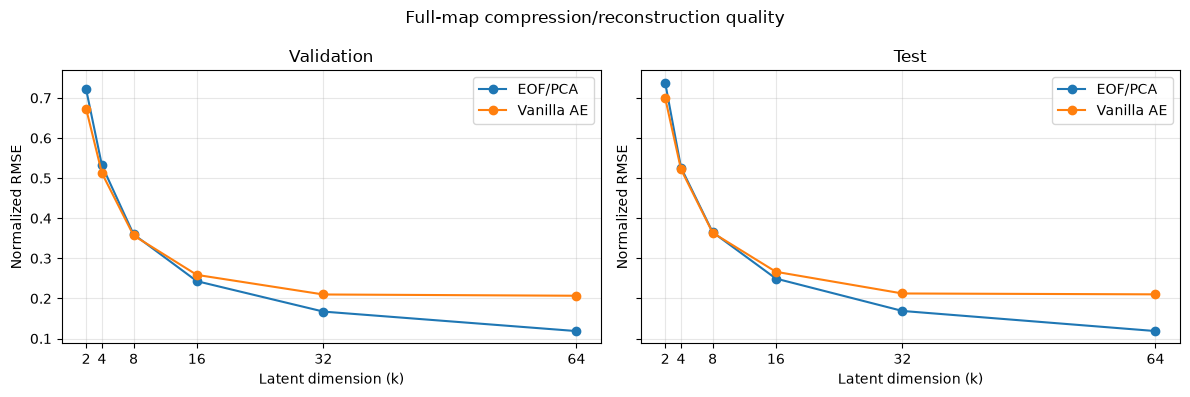

RMSE plot findings (lower is better):
  Validation: at k=64, EOF/PCA has the lower normalized RMSE (0.11861).
    EOF/PCA: RMSE changes from 0.72138 at k=2 to 0.11861 at k=64.
    Vanilla AE: RMSE changes from 0.67309 at k=2 to 0.20674 at k=64.
  Test: at k=64, EOF/PCA has the lower normalized RMSE (0.11866).
    EOF/PCA: RMSE changes from 0.73785 at k=2 to 0.11866 at k=64.
    Vanilla AE: RMSE changes from 0.69935 at k=2 to 0.21021 at k=64.


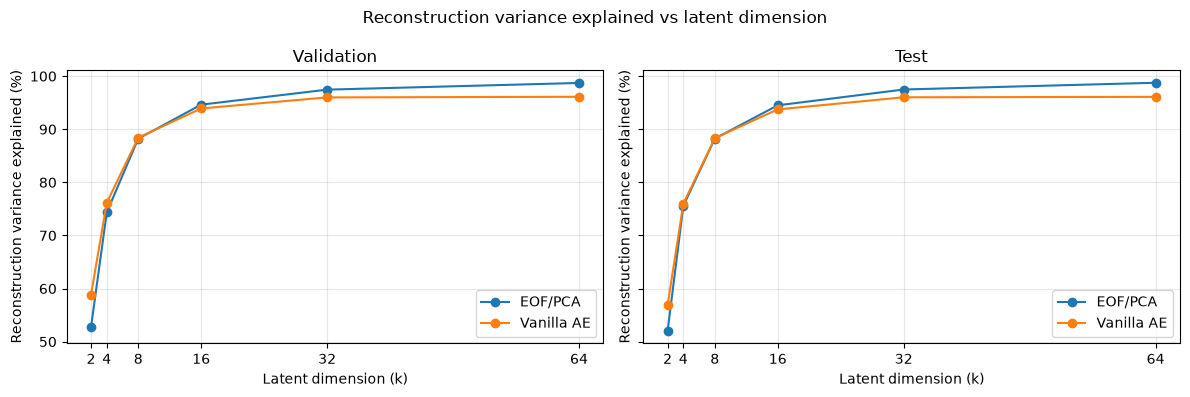

Variance plot findings (higher is better):
  Values are held-out R²-style variance explained: 100 × (1 − SSE/SST), computed against each split's own mean baseline; negative values mean worse than that baseline.
  Validation: at k=64, EOF/PCA explains more variance (98.72%).
    EOF/PCA: explained variance changes from 52.73% at k=2 to 98.72% at k=64.
    Vanilla AE: explained variance changes from 58.85% at k=2 to 96.12% at k=64.
  Test: at k=64, EOF/PCA explains more variance (98.76%).
    EOF/PCA: explained variance changes from 51.99% at k=2 to 98.76% at k=64.
    Vanilla AE: explained variance changes from 56.87% at k=2 to 96.10% at k=64.


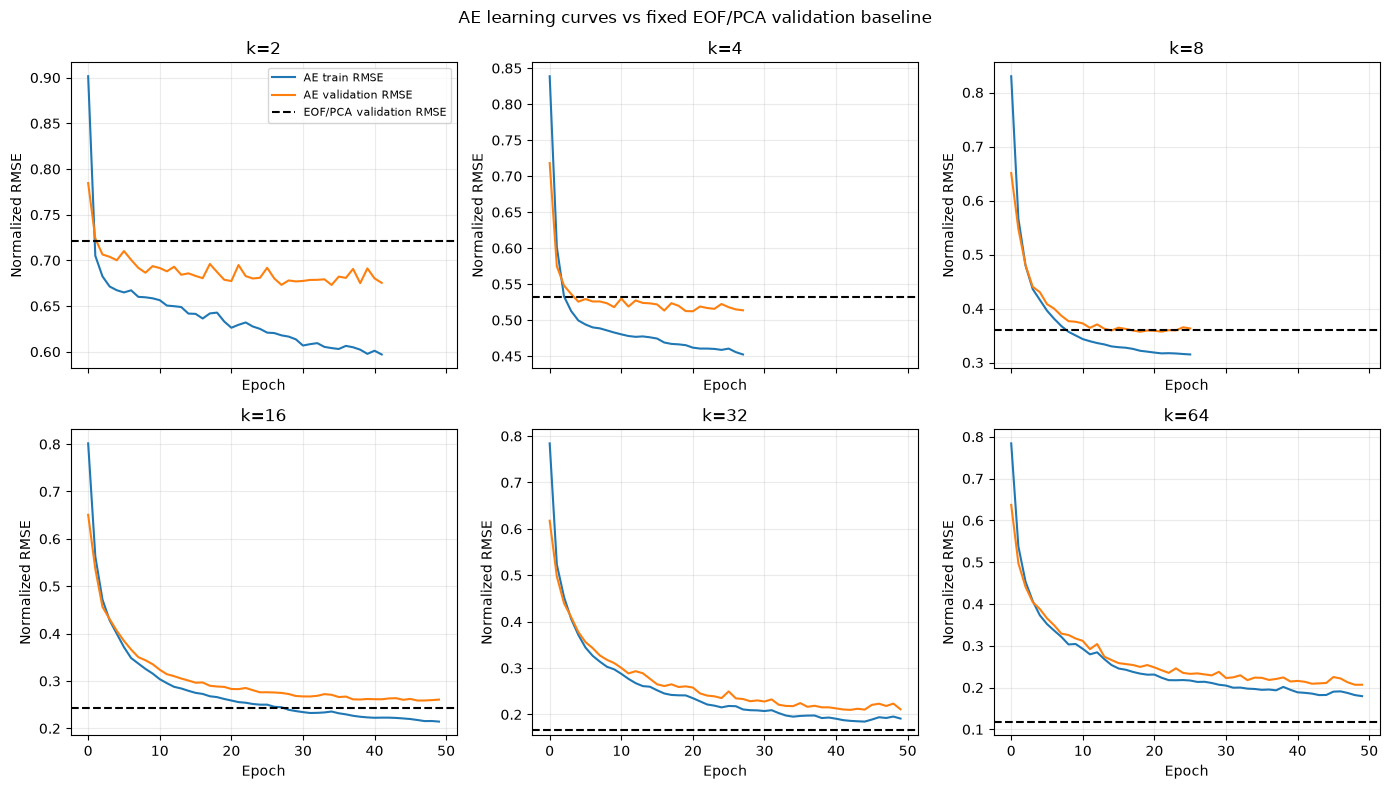

Learning-curve finding: at k=16, AE reaches its lowest validation RMSE (0.25875) at epoch 47, above or equal to the fixed EOF/PCA validation RMSE (0.24308).


In [16]:
from IPython.display import HTML, display
from html import escape

def show_html_table(headers, rows, caption):
    header_html = "".join(f"<th style='border:1px solid #bbb;padding:5px'>{escape(str(v))}</th>" for v in headers)
    row_html = "".join("<tr>" + "".join(f"<td style='border:1px solid #bbb;padding:5px'>{escape(str(v))}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table style='border-collapse:collapse;width:100%'><caption style='font-weight:bold;padding:6px'>{escape(caption)}</caption><thead><tr>{header_html}</tr></thead><tbody>{row_html}</tbody></table>"))

rows=[]
for split in ("validation", "test"):
    for k in LATENT_SIZES:
        for method, results in (("EOF/PCA", pca_metrics), ("Vanilla AE", ae_metrics)):
            metrics=results[split][k]
            rows.append((split.title(),method,k,f"{metrics['normalized_rmse']:.5f}",*(f"{metrics['per_variable_rmse'][v]:.4g}" for v in VARIABLES)))
show_html_table(("Split","Method","k","Normalized RMSE",*(f"{v} RMSE ({UNITS[v]})" for v in VARIABLES)), rows, "Full-map reconstruction RMSE on identical maps")

fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,split in zip(axes,("validation","test")):
    ax.plot(LATENT_SIZES,[pca_metrics[split][k]["normalized_rmse"] for k in LATENT_SIZES],marker="o",label="EOF/PCA")
    ax.plot(LATENT_SIZES,[ae_metrics[split][k]["normalized_rmse"] for k in LATENT_SIZES],marker="o",label="Vanilla AE")
    ax.set(title=split.title(),xlabel="Latent dimension (k)",ylabel="Normalized RMSE")
    ax.set_xticks(LATENT_SIZES); ax.grid(alpha=.3); ax.legend()
fig.suptitle("Full-map compression/reconstruction quality"); fig.tight_layout()
fig.savefig(OUTPUT_DIR/"era5_ae_eof_compression_rmse.png",dpi=160); plt.show()

print("RMSE plot findings (lower is better):")
for split in ("validation", "test"):
    k = max(LATENT_SIZES)
    winner = min((("EOF/PCA", pca_metrics), ("Vanilla AE", ae_metrics)),
                 key=lambda item: item[1][split][k]["normalized_rmse"])
    print(f"  {split.title()}: at k={k}, {winner[0]} has the lower normalized RMSE "
          f"({winner[1][split][k]['normalized_rmse']:.5f}).")
    for method, results in (("EOF/PCA", pca_metrics), ("Vanilla AE", ae_metrics)):
        first = results[split][min(LATENT_SIZES)]["normalized_rmse"]
        last = results[split][k]["normalized_rmse"]
        print(f"    {method}: RMSE changes from {first:.5f} at k={min(LATENT_SIZES)} "
              f"to {last:.5f} at k={k}.")

fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,split in zip(axes,("validation","test")):
    ax.plot(LATENT_SIZES,[pca_metrics[split][k]["variance_explained_pct"] for k in LATENT_SIZES],marker="o",label="EOF/PCA")
    ax.plot(LATENT_SIZES,[ae_metrics[split][k]["variance_explained_pct"] for k in LATENT_SIZES],marker="o",label="Vanilla AE")
    ax.set(title=split.title(),xlabel="Latent dimension (k)",ylabel="Reconstruction variance explained (%)")
    ax.set_xticks(LATENT_SIZES); ax.grid(alpha=.3); ax.legend()
fig.suptitle("Reconstruction variance explained vs latent dimension")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"era5_ae_eof_compression_variance_explained.png",dpi=160); plt.show()

print("Variance plot findings (higher is better):")
print("  Values are held-out R²-style variance explained: 100 × (1 − SSE/SST), "
      "computed against each split's own mean baseline; negative values mean worse than that baseline.")
for split in ("validation", "test"):
    k = max(LATENT_SIZES)
    winner = max((("EOF/PCA", pca_metrics), ("Vanilla AE", ae_metrics)),
                 key=lambda item: item[1][split][k]["variance_explained_pct"])
    print(f"  {split.title()}: at k={k}, {winner[0]} explains more variance "
          f"({winner[1][split][k]['variance_explained_pct']:.2f}%).")
    for method, results in (("EOF/PCA", pca_metrics), ("Vanilla AE", ae_metrics)):
        first = results[split][min(LATENT_SIZES)]["variance_explained_pct"]
        last = results[split][k]["variance_explained_pct"]
        print(f"    {method}: explained variance changes from {first:.2f}% at "
              f"k={min(LATENT_SIZES)} to {last:.2f}% at k={k}.")

fig,axes=plt.subplots(2,3,figsize=(14,8),sharex=True)
for ax,k in zip(axes.flat,LATENT_SIZES):
    h=ae_histories[k]
    ax.plot(np.sqrt(h["train"]),label="AE train RMSE")
    ax.plot(np.sqrt(h["validation"]),label="AE validation RMSE")
    ax.axhline(pca_metrics["validation"][k]["normalized_rmse"],color="black",linestyle="--",label="EOF/PCA validation RMSE")
    ax.set(title=f"k={k}",xlabel="Epoch",ylabel="Normalized RMSE"); ax.grid(alpha=.25)
axes.flat[0].legend(fontsize=8)
fig.suptitle("AE learning curves vs fixed EOF/PCA validation baseline"); fig.tight_layout()
fig.savefig(OUTPUT_DIR/"era5_ae_epoch_rmse_vs_eof.png",dpi=160); plt.show()
best_epoch = int(np.argmin(ae_histories[COMPRESSION_LATENT_SIZE]["validation"])) + 1
best_ae_rmse = float(np.sqrt(min(ae_histories[COMPRESSION_LATENT_SIZE]["validation"])))
pca_baseline_rmse = pca_metrics["validation"][COMPRESSION_LATENT_SIZE]["normalized_rmse"]
relation = "below" if best_ae_rmse < pca_baseline_rmse else "above or equal to"
print(f"Learning-curve finding: at k={COMPRESSION_LATENT_SIZE}, AE reaches its lowest "
      f"validation RMSE ({best_ae_rmse:.5f}) at epoch {best_epoch}, {relation} the "
      f"fixed EOF/PCA validation RMSE ({pca_baseline_rmse:.5f}).")

In [17]:
rows = []
for k in LATENT_SIZES:
    for variable in ("normalized", *VARIABLES):
        def value(result):
            return result["normalized_rmse"] if variable == "normalized" else result["per_variable_rmse"][variable]
        values = np.array([value(ae_seed_metrics[seed]["test"][k]) for seed in SEEDS])
        rows.append((k, variable, f"{value(pca_metrics['test'][k]):.5f}", f"{values.mean():.5f}", f"{values.std(ddof=1):.5f}"))
show_html_table(("k", "Variable", "EOF/PCA RMSE", "AE mean RMSE", "AE seed SD"), rows,
                "Experiment 1: held-out 2024 reconstruction (3 seeds)")
print("Conclusion: report which method wins at each k; nonlinear models need not beat EOF/PCA.")
print("The SD measures training-seed variability, not a confidence interval over weather events.")

k,Variable,EOF/PCA RMSE,AE mean RMSE,AE seed SD
2,normalized,0.73785,0.69490,0.00509
2,t2m,1.05935,1.08753,0.01420
2,d2m,1.86386,1.91462,0.03517
2,msl,697.23993,637.93125,22.24967
2,u10,5.09237,4.14633,0.15461
2,v10,4.07766,3.97950,0.07080
4,normalized,0.52636,0.51827,0.00416
4,t2m,0.88888,0.84836,0.01747
4,d2m,1.63343,1.53113,0.02210
4,msl,305.55518,356.30046,14.55402


Conclusion: report which method wins at each k; nonlinear models need not beat EOF/PCA.
The SD measures training-seed variability, not a confidence interval over weather events.


# Experiment 2 — next-day forecasting
Fix the representation at `k=16`. Use the reference AE encoder trained in Experiment 1 and freeze it. Train an encoder-only Transformer on seven historical latent vectors to predict the next vector. A reconstruction decoder converts it back into a map. This is supervised forecasting. Non-causal attention within the seven observed days is valid: the target is never included.

Compare on identical 2024 target dates against: (1) zero anomaly = training climatology; (2) yesterday's anomaly carried forward; (3) yesterday's physical map carried forward. Each forecast is one day ahead, not a seven-day forecast. The first seven days of each split are excluded.

AE Transformer epoch 1: train=0.75835 val=0.53096
AE Transformer epoch 10: train=0.40028 val=0.41275
AE Transformer epoch 20: train=0.32902 val=0.43302
PCA Transformer epoch 1: train=0.91346 val=0.73769
PCA Transformer epoch 10: train=0.56362 val=0.61986
PCA Transformer epoch 20: train=0.47418 val=0.63879


Forecast method,Normalized RMSE,t2m RMSE (K),d2m RMSE (K),msl RMSE (Pa),u10 RMSE (m s$^{-1}$),v10 RMSE (m s$^{-1}$)
AE + Transformer,0.67715,1.006,1.81,676.7,3.782,4.198
EOF/PCA + Transformer,0.68144,1.03,1.837,692.6,3.804,4.107
Anomaly persistence,0.87063,1.288,2.55,773.2,4.546,5.536
Physical-map persistence,0.87069,1.288,2.55,772.8,4.548,5.535
Climatology,1.06574,1.647,2.804,1302,5.702,5.798


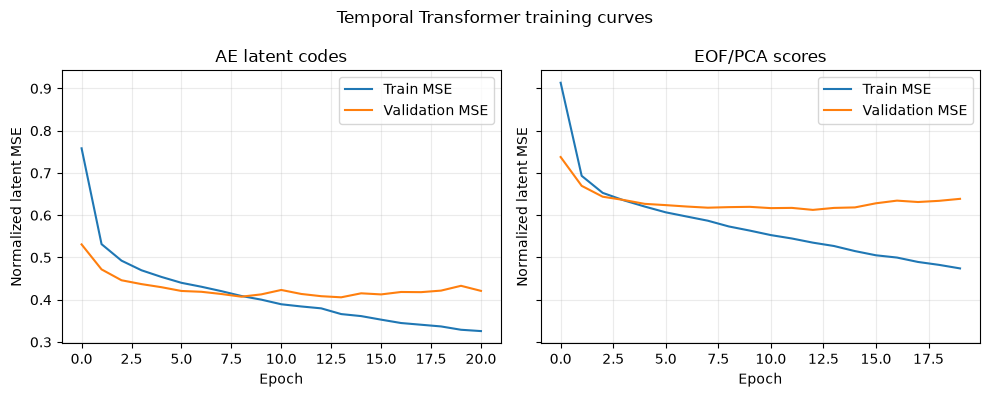

In [18]:
SEQUENCE_LENGTH=7
FORECAST_K=COMPRESSION_LATENT_SIZE
FORECAST_BATCH_SIZE=64
FORECAST_EPOCHS=50
FORECAST_PATIENCE=7

def sequence_pairs(codes,date_array):
    xs,ys,indices=[],[],[]
    for target_i in range(SEQUENCE_LENGTH,len(codes)):
        elapsed=int((date_array[target_i]-date_array[target_i-SEQUENCE_LENGTH]).astype("timedelta64[D]").astype(int))
        if elapsed==SEQUENCE_LENGTH:
            xs.append(codes[target_i-SEQUENCE_LENGTH:target_i]); ys.append(codes[target_i]); indices.append(target_i)
    if not xs: raise ValueError("No contiguous daily sequences found in split.")
    return np.asarray(xs,np.float32),np.asarray(ys,np.float32),np.asarray(indices)

class LatentTransformer(nn.Module):
    def __init__(self,k,width=64,heads=4,layers=2):
        super().__init__()
        self.input=nn.Linear(k,width)
        self.position=nn.Parameter(torch.zeros(1,SEQUENCE_LENGTH,width))
        layer=nn.TransformerEncoderLayer(d_model=width,nhead=heads,dim_feedforward=128,dropout=.1,batch_first=True,activation="gelu")
        self.transformer=nn.TransformerEncoder(layer,num_layers=layers)
        self.head=nn.Linear(width,k)
    def forward(self,x): return self.head(self.transformer(self.input(x)+self.position)[:,-1])

def normalize_codes(code_splits):
    mean=code_splits["train"].mean(axis=0,keepdims=True)
    scale=code_splits["train"].std(axis=0,keepdims=True)
    scale=np.where(scale>1e-6,scale,1.0)
    return {s:((z-mean)/scale).astype(np.float32) for s,z in code_splits.items()},mean.astype(np.float32),scale.astype(np.float32)

def fit_latent_transformer(name,norm_codes,run_seed=42):
    pairs={s:sequence_pairs(norm_codes[s],dates[s]) for s in SPLIT_YEARS}
    tr_x,tr_y,_=pairs["train"]; va_x,va_y,_=pairs["validation"]; te_x,_,target_ids=pairs["test"]
    tr_x=torch.tensor(tr_x,device=DEVICE); tr_y=torch.tensor(tr_y,device=DEVICE)
    va_x=torch.tensor(va_x,device=DEVICE); va_y=torch.tensor(va_y,device=DEVICE)
    torch.manual_seed(run_seed+(0 if name=="AE" else 1000))
    model=LatentTransformer(FORECAST_K).to(DEVICE); opt=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-5)
    best=float("inf"); state=None; stale=0; history={"train":[],"validation":[]}
    for epoch in range(1,FORECAST_EPOCHS+1):
        model.train(); order=torch.randperm(len(tr_x),device=DEVICE); total=0.0
        for start in range(0,len(order),FORECAST_BATCH_SIZE):
            ix=order[start:start+FORECAST_BATCH_SIZE]; opt.zero_grad(set_to_none=True)
            loss=nn.functional.mse_loss(model(tr_x[ix]),tr_y[ix]); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step(); total+=float(loss.detach().cpu())*len(ix)
        tr_loss=total/len(tr_x); model.eval()
        with torch.inference_mode(): va_loss=float(nn.functional.mse_loss(model(va_x),va_y).cpu())
        history["train"].append(tr_loss); history["validation"].append(va_loss)
        if va_loss<best:
            best=va_loss; state={n:t.detach().cpu().clone() for n,t in model.state_dict().items()}; stale=0
        else: stale+=1
        if epoch==1 or epoch%10==0: print(f"{name} Transformer epoch {epoch}: train={tr_loss:.5f} val={va_loss:.5f}")
        if stale>=FORECAST_PATIENCE: break
    if state is None: raise RuntimeError(f"No forecast checkpoint for {name}.")
    model.load_state_dict(state); model.eval(); test_x=torch.tensor(te_x,device=DEVICE)
    with torch.inference_mode(): prediction=np.concatenate([model(test_x[s:s+FORECAST_BATCH_SIZE]).cpu().numpy() for s in range(0,len(test_x),FORECAST_BATCH_SIZE)])
    torch.save({"state_dict":state,"method":name,"sequence_length":SEQUENCE_LENGTH,"best_validation_mse":best},OUTPUT_DIR/f"era5_{name.lower()}_latent_transformer_k{FORECAST_K}_seed{run_seed}.pt")
    del model,opt; gc.collect()
    return prediction,target_ids,history

pca_codes={s:((X[s].detach().cpu()-pca_mean)@pca_components[:,:FORECAST_K]).numpy() for s in SPLIT_YEARS}
ae_norm,ae_code_mean,ae_code_scale=normalize_codes(latent_codes)
pca_norm,pca_code_mean,pca_code_scale=normalize_codes(pca_codes)
ae_pred_norm,ae_target_ids,ae_forecast_history=fit_latent_transformer("AE",ae_norm)
pca_pred_norm,pca_target_ids,pca_forecast_history=fit_latent_transformer("PCA",pca_norm)
if not np.array_equal(ae_target_ids,pca_target_ids): raise RuntimeError("AE/PCA target dates differ.")
test_target_ids=ae_target_ids
forecast_dates=dates["test"][test_target_ids]
ae_pred_codes=ae_pred_norm*ae_code_scale+ae_code_mean
pca_pred_codes=pca_pred_norm*pca_code_scale+pca_code_mean

checkpoint=torch.load(OUTPUT_DIR/f"era5_vanilla_5var_k{FORECAST_K}_seed{SEEDS[0]}.pt",map_location="cpu",weights_only=True)
ae_decoder=DenseAutoencoder(n_features,FORECAST_K).to(DEVICE); ae_decoder.load_state_dict(checkpoint["state_dict"]); ae_decoder.eval()
with torch.inference_mode(): ae_pred_std=ae_decoder.decoder(torch.tensor(ae_pred_codes,dtype=torch.float32,device=DEVICE)).cpu().numpy()
pca_pred_std=(pca_mean.numpy()[None,:]+pca_pred_codes@pca_components[:,:FORECAST_K].numpy().T)
actual_std=standardized["test"][test_target_ids]
persistence_std=standardized["test"][test_target_ids-1]
target_climatology = np.stack([climatology[key] for key in month_day_keys(forecast_dates)])
physical_persistence_std = (raw_maps["test"][test_target_ids-1] - target_climatology) / variable_scales[None,:,None,None]

def forecast_rmse(pred,target):
    e=(pred-target)*variable_scales[None,:,None,None]
    per=np.sqrt(np.mean(e**2,axis=(0,2,3)))
    return float(np.sqrt(np.mean((pred-target)**2))),dict(zip(VARIABLES,per.astype(float)))
forecast_maps={
    "AE + Transformer":ae_pred_std.reshape(-1,n_variables,height,width),
    "EOF/PCA + Transformer":pca_pred_std.reshape(-1,n_variables,height,width),
    "Anomaly persistence":persistence_std,
    "Physical-map persistence":physical_persistence_std,
    "Climatology":np.zeros_like(actual_std),
}
forecast_metrics={name:forecast_rmse(value.reshape(actual_std.shape),actual_std) for name,value in forecast_maps.items()}
forecast_rows=[(name,f"{m[0]:.5f}",*(f"{m[1][v]:.4g}" for v in VARIABLES)) for name,m in forecast_metrics.items()]
show_html_table(("Forecast method","Normalized RMSE",*(f"{v} RMSE ({UNITS[v]})" for v in VARIABLES)),forecast_rows,"2024 next-day maps: shared target dates")
fig,axes=plt.subplots(1,2,figsize=(10,4),sharey=True)
for ax,(name,hist) in zip(axes,(("AE latent codes",ae_forecast_history),("EOF/PCA scores",pca_forecast_history))):
    ax.plot(hist["train"],label="Train MSE"); ax.plot(hist["validation"],label="Validation MSE")
    ax.set(title=name,xlabel="Epoch",ylabel="Normalized latent MSE"); ax.grid(alpha=.25); ax.legend()
fig.suptitle("Temporal Transformer training curves"); fig.tight_layout(); plt.show()

### Forecast variability across three Transformer seeds
Keep the compression models fixed and vary Transformer initialization/training only. These seed standard deviations describe forecasting-model training variability, not variability from refitting the compression representation.

In [19]:
forecast_seed_metrics = {SEEDS[0]: {name: forecast_metrics[name] for name in ("AE + Transformer", "EOF/PCA + Transformer")}}
for run_seed in SEEDS[1:]:
    seed_results = {}
    for name, norm, mean, scale in (("AE", ae_norm, ae_code_mean, ae_code_scale), ("PCA", pca_norm, pca_code_mean, pca_code_scale)):
        pred, ids, _ = fit_latent_transformer(name, norm, run_seed=run_seed)
        assert np.array_equal(ids, test_target_ids)
        codes = pred * scale + mean
        if name == "AE":
            with torch.inference_mode():
                decoded = ae_decoder.decoder(torch.tensor(codes, dtype=torch.float32, device=DEVICE)).cpu().numpy()
        else:
            decoded = pca_mean.numpy()[None, :] + codes @ pca_components[:, :FORECAST_K].numpy().T
        label = "AE + Transformer" if name == "AE" else "EOF/PCA + Transformer"
        seed_results[label] = forecast_rmse(decoded.reshape(actual_std.shape), actual_std)
    forecast_seed_metrics[run_seed] = seed_results
rows = []
for name in ("AE + Transformer", "EOF/PCA + Transformer"):
    for variable in ("normalized", *VARIABLES):
        values = np.array([forecast_seed_metrics[seed][name][0] if variable == "normalized" else forecast_seed_metrics[seed][name][1][variable] for seed in SEEDS])
        rows.append((name, variable, f"{values.mean():.5f}", f"{values.std(ddof=1):.5f}"))
show_html_table(("Model", "Variable", "Mean forecast RMSE", "Seed SD"), rows, "Experiment 2: three Transformer seeds with fixed compression")
skill_rows = []
for name in ("AE + Transformer", "EOF/PCA + Transformer"):
    rmse = np.mean([forecast_seed_metrics[seed][name][0] for seed in SEEDS])
    for baseline in ("Climatology", "Anomaly persistence", "Physical-map persistence"):
        baseline_rmse = forecast_metrics[baseline][0]
        skill_rows.append((name, baseline, f"{100*(1-rmse/baseline_rmse):.2f}%" if baseline_rmse > 0 else "undefined"))
show_html_table(("Model", "Baseline", "RMSE reduction"), skill_rows, "Positive percentage = lower RMSE than baseline; negative = worse")
print("Conclusion: distinguish AE/PCA representation quality from downstream forecasting skill.")
print("A model must improve on the relevant forecast baseline before claiming useful predictive skill.")

AE Transformer epoch 1: train=0.75249 val=0.52451
AE Transformer epoch 10: train=0.40318 val=0.40886
PCA Transformer epoch 1: train=0.92066 val=0.73868
PCA Transformer epoch 10: train=0.56267 val=0.61184
PCA Transformer epoch 20: train=0.47602 val=0.62842
AE Transformer epoch 1: train=0.76654 val=0.52916
AE Transformer epoch 10: train=0.40318 val=0.41352
AE Transformer epoch 20: train=0.33297 val=0.42320
PCA Transformer epoch 1: train=0.87806 val=0.71981
PCA Transformer epoch 10: train=0.56217 val=0.60814


Model,Variable,Mean forecast RMSE,Seed SD
AE + Transformer,normalized,0.68117,0.00354
AE + Transformer,t2m,1.01563,0.01211
AE + Transformer,d2m,1.84050,0.02847
AE + Transformer,msl,673.96602,3.02926
AE + Transformer,u10,3.79860,0.01865
AE + Transformer,v10,4.20201,0.03223
EOF/PCA + Transformer,normalized,0.68163,0.00210
EOF/PCA + Transformer,t2m,1.03080,0.00205
EOF/PCA + Transformer,d2m,1.83474,0.00560
EOF/PCA + Transformer,msl,690.61713,5.32774


Model,Baseline,RMSE reduction
AE + Transformer,Climatology,36.08%
AE + Transformer,Anomaly persistence,21.76%
AE + Transformer,Physical-map persistence,21.77%
EOF/PCA + Transformer,Climatology,36.04%
EOF/PCA + Transformer,Anomaly persistence,21.71%
EOF/PCA + Transformer,Physical-map persistence,21.71%


Conclusion: distinguish AE/PCA representation quality from downstream forecasting skill.
A model must improve on the relevant forecast baseline before claiming useful predictive skill.


# Separate geographic figures
The following figures use one illustrative date. Overall conclusions must use all held-out dates and the seed tables. ERA5 is the reference reanalysis, rather than independent station observations. Skip this cell if Cartopy or coastline data are unavailable.

In [20]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

REQUESTED_MAP_DATE=np.datetime64("2024-07-15","D")
match=np.flatnonzero(forecast_dates==REQUESTED_MAP_DATE)
forecast_i=int(match[0]) if len(match) else len(forecast_dates)//2
test_i=int(test_target_ids[forecast_i]); target_date=dates["test"][test_i]
ae_decoder=ae_decoder.to(DEVICE)
ae_recon=predict_in_batches(ae_decoder,X["test"][test_i:test_i+1]).reshape(n_variables,height,width)
pca_score=(X["test"][test_i].detach().cpu()-pca_mean)@pca_components[:,:FORECAST_K]
pca_recon=(pca_mean+pca_score@pca_components[:,:FORECAST_K].T).numpy().reshape(n_variables,height,width)
def physical_map(z,date):
    key=np.datetime_as_string(date,unit="D")[5:]
    if key not in climatology: raise KeyError(f"Missing training climatology for {key}")
    return z*variable_scales[:,None,None]+climatology[key]
actual=raw_maps["test"][test_i]

s:\git-repo\pgr\py-torch\.venv\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


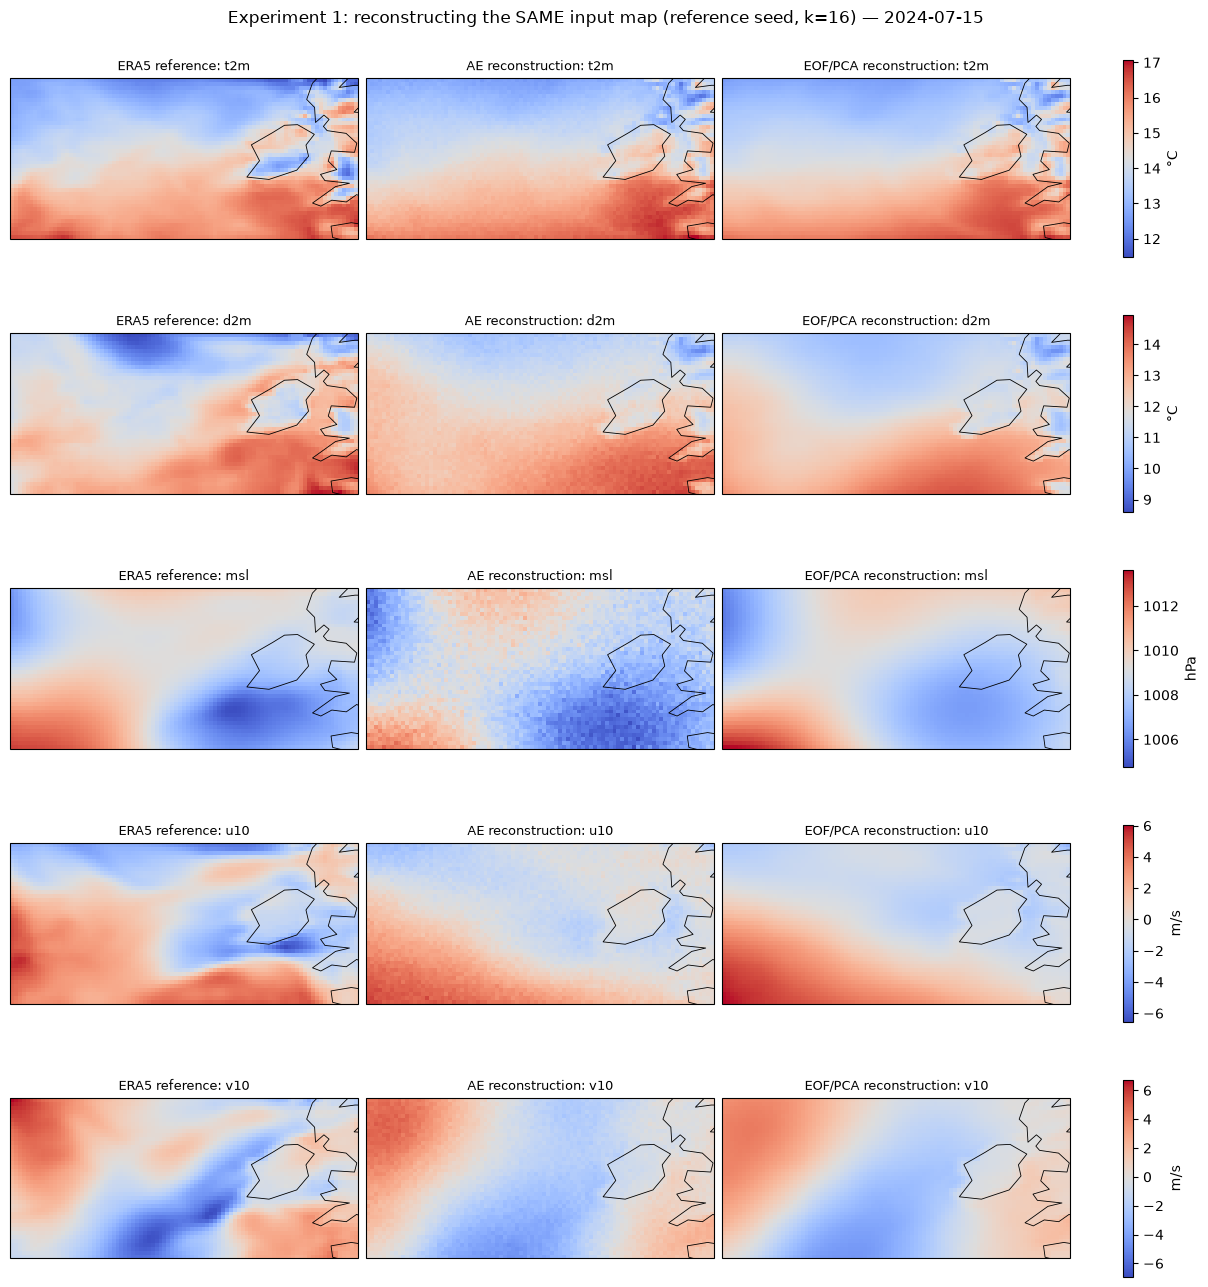

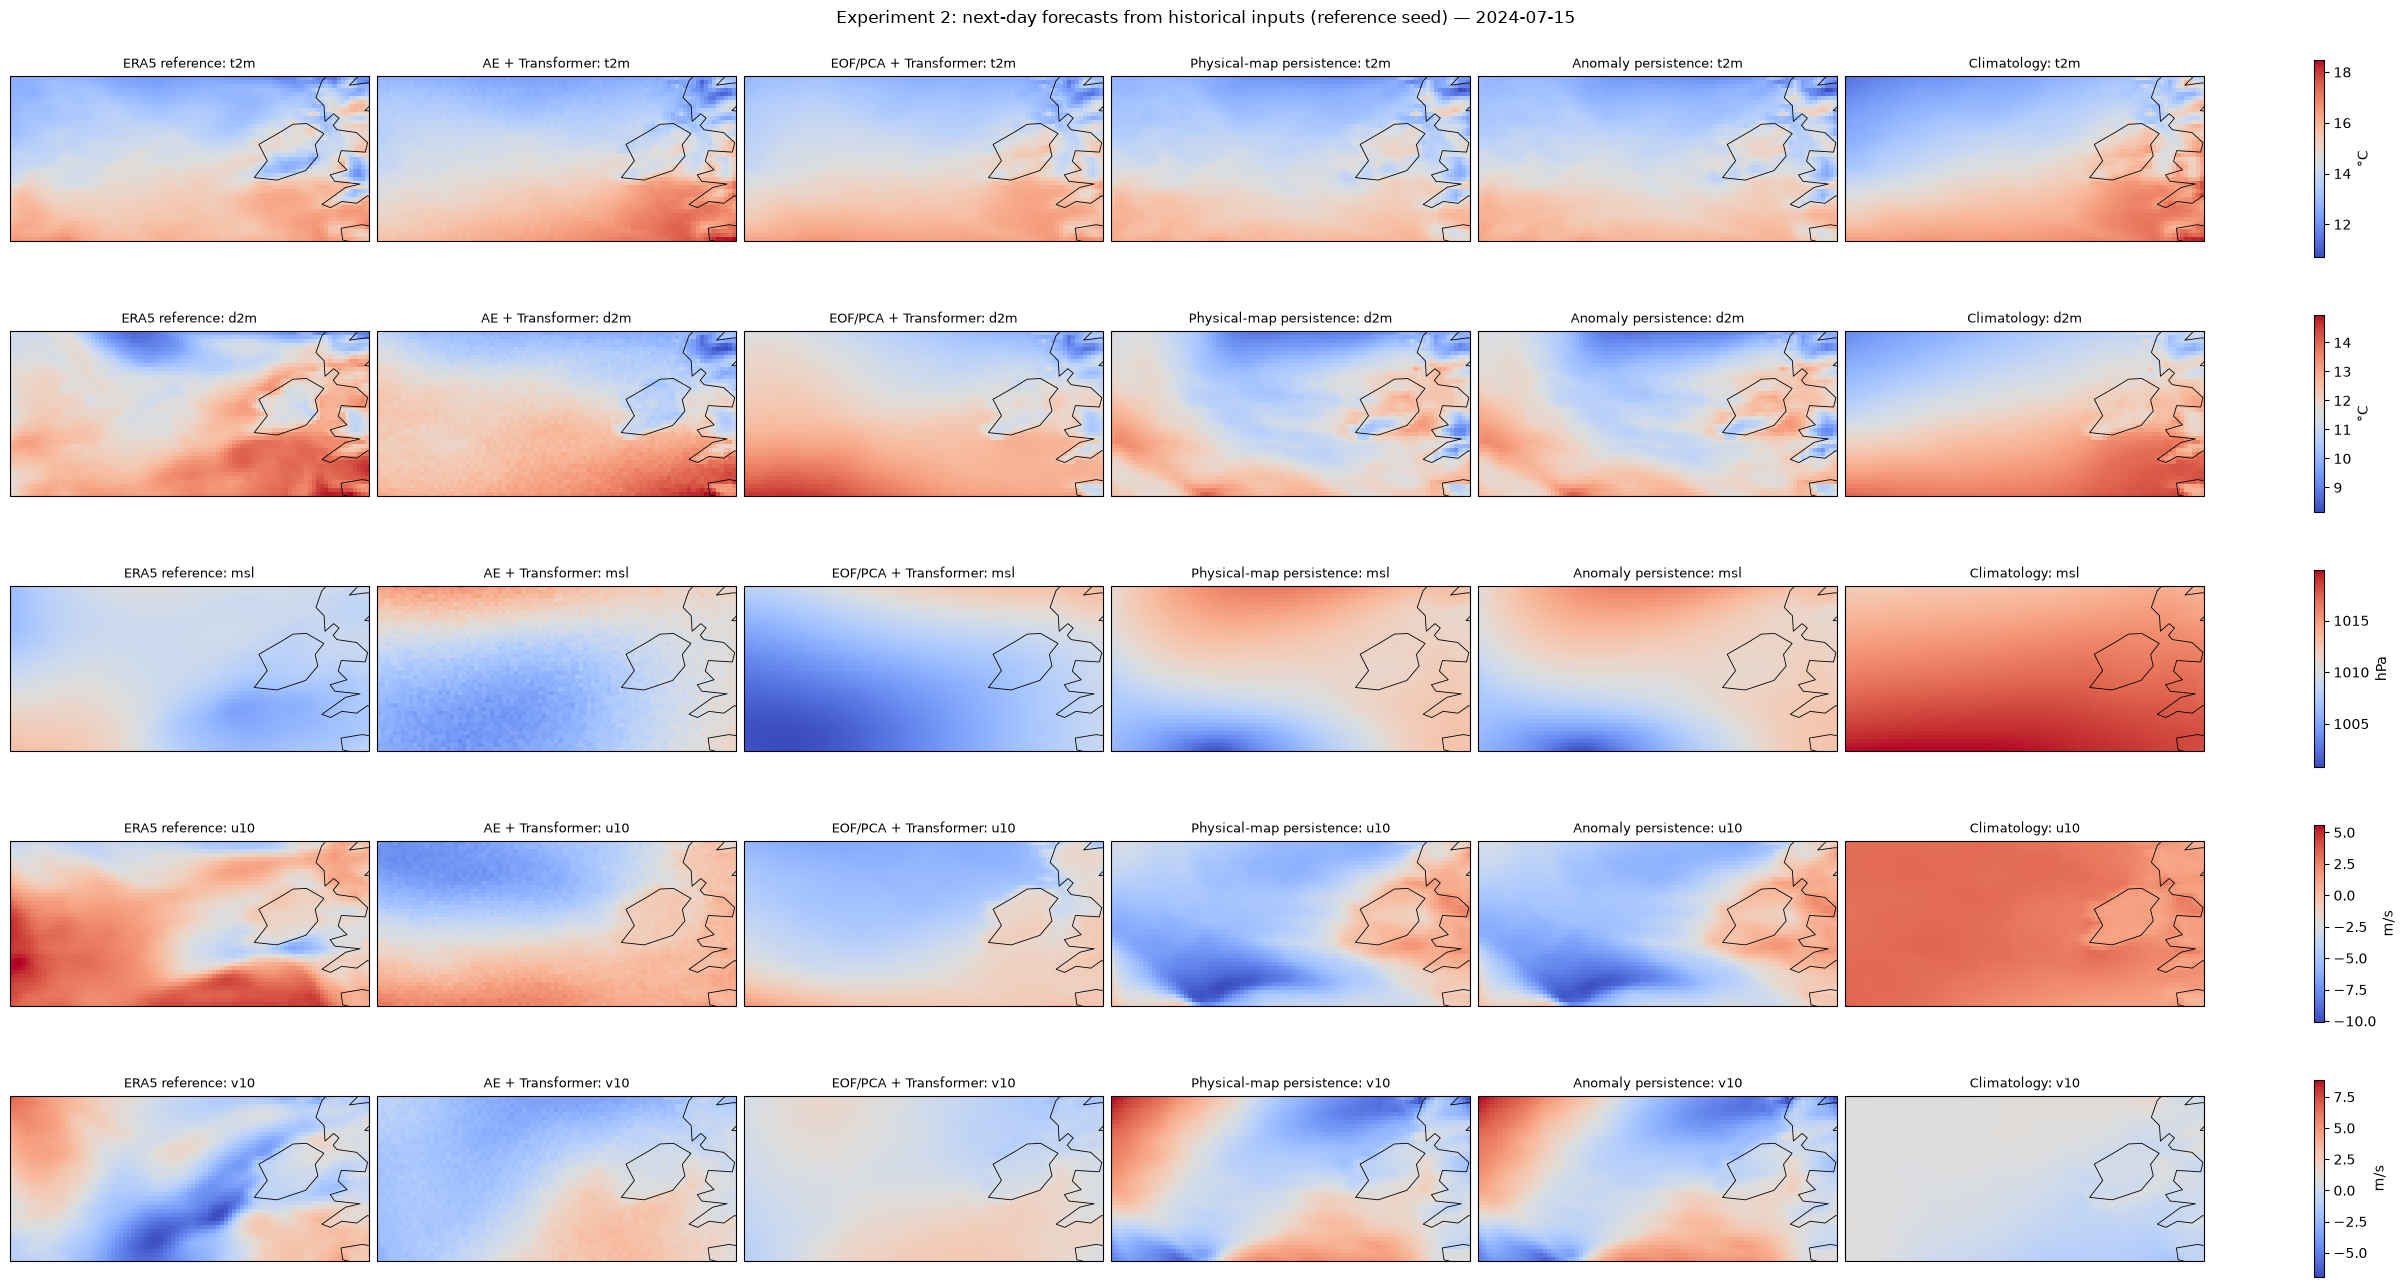

In [21]:
def plot_map_comparison(columns, title, filename):
    fig, axes = plt.subplots(n_variables, len(columns), figsize=(4*len(columns), 13),
                             squeeze=False, constrained_layout=True,
                             subplot_kw={"projection": ccrs.PlateCarree()})
    for vi, variable in enumerate(VARIABLES):
        fields = [cube[vi].copy() for _, cube in columns]
        unit = "m/s"
        if variable in ("t2m", "d2m"):
            fields = [field-273.15 for field in fields]; unit = "°C"
        elif variable == "msl":
            fields = [field/100 for field in fields]; unit = "hPa"
        low, high = min(float(f.min()) for f in fields), max(float(f.max()) for f in fields)
        for ci, ((label, _), field) in enumerate(zip(columns, fields)):
            ax = axes[vi, ci]
            im = ax.pcolormesh(longitude, latitude, field, shading="auto", cmap="coolwarm", vmin=low, vmax=high, transform=ccrs.PlateCarree())
            ax.coastlines(resolution="110m", linewidth=.6)
            ax.set_title(f"{label}: {variable}", fontsize=9)
        fig.colorbar(im, ax=list(axes[vi]), label=unit, shrink=.8)
    fig.suptitle(f"{title} — {target_date}")
    fig.savefig(OUTPUT_DIR/filename, dpi=150)
    plt.show()

plot_map_comparison([
    ("ERA5 reference", actual),
    ("AE reconstruction", physical_map(ae_recon, target_date)),
    ("EOF/PCA reconstruction", physical_map(pca_recon, target_date))],
    "Experiment 1: reconstructing the SAME input map (reference seed, k=16)", "experiment1_reconstruction_maps.png")

plot_map_comparison([
    ("ERA5 reference", actual),
    *[(name, physical_map(forecast_maps[name][forecast_i], target_date))
      for name in ("AE + Transformer", "EOF/PCA + Transformer", "Physical-map persistence", "Anomaly persistence", "Climatology")]],
    "Experiment 2: next-day forecasts from historical inputs (reference seed)", "experiment2_forecast_maps.png")

# Interpretation and five-minute presentation

1. **Question and data (45 s):** daily ERA5 maps, variables, domain and chronological split.
2. **Experiment 1 (90 s):** show the AE bottleneck, EOF/PCA baseline, RMSE versus latent size, and one reconstruction figure. State where each method wins.
3. **Experiment 2 (90 s):** explain seven previous days → next day. Show physical-unit RMSE and baseline skill. Keep this as an extension if time is tight.
4. **Conclusions and limitations (75 s):** distinguish compression from prediction. Explain seed variability, the short climatology reference, daily averaging, and unweighted grid metrics. Reconstruction variance explained is `100*(1-SSE/SST)` on held-out data, not PCA's cumulative eigenvalue ratio. Neither a low RMSE nor a single attractive map establishes skill on extremes.

**Fill in after running:** Which model won at equal k? Did either Transformer beat physical persistence and climatology? Were the differences large compared with seed variation? Which variable was hardest to reconstruct or forecast?

## Save preprocessing and summaries
Checkpoints alone are insufficient for reuse. The final cell saves coordinates, climatology, variable scales, PCA basis, latent normalization and numerical metric summaries alongside the model checkpoints. No results from the previous notebook are reused.

In [12]:
import json
np.savez_compressed(OUTPUT_DIR/"era5_preprocessing.npz",
    variables=np.array(VARIABLES), latitude=latitude, longitude=longitude,
    calendar_keys=np.array(sorted(climatology)),
    climatology=np.stack([climatology[key] for key in sorted(climatology)]),
    variable_scales=variable_scales, pca_mean=pca_mean.numpy(),
    pca_components=pca_components.numpy(), ae_code_mean=ae_code_mean,
    ae_code_scale=ae_code_scale, pca_code_mean=pca_code_mean, pca_code_scale=pca_code_scale,
    seeds=np.array(SEEDS), sequence_length=SEQUENCE_LENGTH, forecast_k=FORECAST_K)
summary = {"ae_reconstruction": ae_seed_metrics, "pca_reconstruction": pca_metrics,
           "transformer_forecasts": forecast_seed_metrics, "reference_forecasts_and_baselines": forecast_metrics}
(OUTPUT_DIR/"era5_metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved preprocessing, model checkpoints, figures, and metric summaries to", OUTPUT_DIR)

Saved preprocessing, model checkpoints, figures, and metric summaries to d:\PhD\era5_temperature_project\model
